# KOTE 감정 분류 결과 비교: LSTM vs KcBERT vs KcELECTRA(제작자)

- `01_lstm_from_scratch.ipynb`, `02_kcbert_finetuning.ipynb`의 **저장된 예측 확률**로만 분석 (재학습 없음)
    - KcBERT: `results/kcbert_{val,test}_probs.npy` (02_kcbert_finetuning.ipynb에서 저장)
    - LSTM: `results/lstm_{val,test}_probs.npy` (`scripts/export_lstm_probs.py`로 과제 1 노트북 셀 0~23을 그대로 다시 실행해 저장)
- KcELECTRA 값은 제작자 저장소(github.com/searle-j/KOTE)의 `codes/KOTE_pytorch_lightning.ipynb` 출력에 찍힌 값 (소수점 둘째 자리)
- 원칙: **threshold 등 모든 선택은 val로**, test는 결과 확인에만 사용
- 그래프는 `results/`에 PNG로 저장

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score

# 한글 폰트 (Windows), 마이너스 기호 깨짐 방지
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

RESULTS = Path("./results")
RESULTS.mkdir(exist_ok=True)

# 모델별 색 (그래프 전체에서 고정)
C_LSTM, C_BERT, C_ELEC = "#eb6834", "#2a78d6", "#1baf7a"
GRID = dict(color="#d9d9d6", linewidth=0.8)

def savefig(fig, name):
    fig.savefig(RESULTS / name, dpi=150, bbox_inches="tight", facecolor="white")
    print("저장:", RESULTS / name)

In [ ]:
# 데이터와 예측 확률 불러오기

LABELS = ['불평/불만','환영/호의','감동/감탄','지긋지긋','고마움','슬픔','화남/분노','존경',
          '기대감','우쭐댐/무시함','안타까움/실망','비장함','의심/불신','뿌듯함','편안/쾌적',
          '신기함/관심','아껴주는','부끄러움','공포/무서움','절망','한심함','역겨움/징그러움',
          '짜증','어이없음','없음','패배/자기혐오','귀찮음','힘듦/지침','즐거움/신남','깨달음',
          '죄책감','증오/혐오','흐뭇함(귀여움/예쁨)','당황/난처','경악','부담/안_내킴','서러움',
          '재미없음','불쌍함/연민','놀람','행복','불안/걱정','기쁨','안심/신뢰']
NUM_LABELS = len(LABELS)

def load_kote(path):
    # 두 노트북과 같은 방식 (pandas, utf-8 명시 → cp949 에러 방지)
    df = pd.read_table(path, names=["ID", "text", "labels"], dtype={"labels": str}, encoding="utf-8")
    y = np.zeros((len(df), NUM_LABELS), dtype=int)
    for i, s in enumerate(df["labels"]):
        y[i, [int(x) for x in s.split(",")]] = 1
    return df, y

train_df, y_train = load_kote("./data/kote/train.tsv")
val_df, y_val = load_kote("./data/kote/val.tsv")
test_df, y_test = load_kote("./data/kote/test.tsv")

probs = {
    "LSTM":   {"val": np.load(RESULTS / "lstm_val_probs.npy"),   "test": np.load(RESULTS / "lstm_test_probs.npy")},
    "KcBERT": {"val": np.load(RESULTS / "kcbert_val_probs.npy"), "test": np.load(RESULTS / "kcbert_test_probs.npy")},
}
lstm_info = json.loads((RESULTS / "lstm_train_info.json").read_text(encoding="utf-8"))

print("test:", test_df.shape, y_test.shape, "| 44개 라벨 모두 등장:", (y_test.sum(0) > 0).all())
for m, d in probs.items():
    print(m, {k: v.shape for k, v in d.items()})

test: (5000, 3) (5000, 44) | 44개 라벨 모두 등장: True
LSTM {'val': (5000, 44), 'test': (5000, 44)}
KcBERT {'val': (5000, 44), 'test': (5000, 44)}


In [ ]:
# 비교 조건 검증

def scores(prob, y, t):
    pred = (prob >= t).astype(int)
    return {
        "micro_f1": f1_score(y, pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "micro_p": precision_score(y, pred, average="micro", zero_division=0),
        "micro_r": recall_score(y, pred, average="micro", zero_division=0),
        "macro_p": precision_score(y, pred, average="macro", zero_division=0),
        "macro_r": recall_score(y, pred, average="macro", zero_division=0),
        "avg_pred": pred.sum(axis=1).mean(),
    }

check = pd.DataFrame([
    {"모델": "LSTM", "노트북 기록": "micro 0.5514 / macro 0.4362 (과제 1)",
     **{k: v for k, v in scores(probs["LSTM"]["test"], y_test, 0.3).items() if k in ("micro_f1", "macro_f1")}},
    {"모델": "KcBERT", "노트북 기록": "micro 0.6361 / macro 0.5368 (Transformer)",
     **{k: v for k, v in scores(probs["KcBERT"]["test"], y_test, 0.3).items() if k in ("micro_f1", "macro_f1")}},
]).set_index("모델")
print("저장된 확률로 다시 계산한 test (threshold 0.3, >=)")
display(check.round(4))
print("LSTM 재실행 정보:", {k: lstm_info[k] for k in ("epochs_run", "best_epoch", "best_val_macro_f1", "train_seconds", "device")})

저장된 확률로 다시 계산한 test (threshold 0.3, >=)


,노트북 기록,micro_f1,macro_f1
모델,,,
LSTM,micro 0.5514 / macro 0.4362 (과제 1),0.5514,0.4362
KcBERT,micro 0.6361 / macro 0.5368 (Transformer),0.6361,0.5368


LSTM 재실행 정보: {'epochs_run': 20, 'best_epoch': 15, 'best_val_macro_f1': 0.4434327942257265, 'train_seconds': 90.6, 'device': 'cuda'}


### 비교 조건 정리표

| 항목 | LSTM | KcBERT | KcELECTRA (제작자 PL 버전) | 판단 |
|---|---|---|---|---|
| test split | KOTE test.tsv 5,000 | 같음 | HF `searle-j/kote` → 로딩 스크립트가 같은 GitHub test.tsv를 내려받음. 감정별 support(2113, 1109, …)도 우리 test와 일치 | 같음 |
| 정답 | 44차원 multi-hot | 같음 (`classes=range(44)`) | `MultiLabelBinarizer()` split별 fit (세 split 모두 44개 라벨이 있어 열 순서 같음) | 같음 |
| threshold | 0.3 (`>=`) | 0.3 (`>=`) | 0.3 (`>`) | 같음 (정확히 0.3인 확률 없음) |
| F1 | sklearn micro/macro, zero_division=0 | 같음 | sklearn `classification_report` macro avg (44개 단순 평균), zero_division=0 | 같음 |
| 모델 선택 | val macro F1 (thr 0.3) 기준 조기종료 | val macro F1 (thr 0.3), 5 epoch 모두 개선 | val loss 기준 체크포인트/조기종료 | 모두 val만 사용, test 미사용 |
| 입력 길이 | 형태소 80 | 토큰 128 | 토큰 512 + 학습 시 10% 토큰 mask/switch 증강 | 모델 설정 차이 (평가 조건 아님) |

## 전체 성능 비교

- threshold 0.3: 제작자와 같은 조건 → 주 비교 기준
- val best: val macro F1이 가장 높은 threshold를 골라 test에 적용 (모델마다 따로)
- KcBERT 학습 시간: `02_kcbert_finetuning.ipynb` 학습 로그의 epoch별 시간 합 (10:36 + 10:34 + 10:33 + 10:32 + 10:42, val 평가 포함)
- LSTM 학습 시간: `scripts/export_lstm_probs.py` 재실행 때 학습 셀 시간 (같은 PC의 GPU, epoch마다 val 평가 포함)
- KcELECTRA: 제작자 출력값 (소수점 둘째 자리), 파라미터는 출력의 `123 M`, 시간은 코드 주석 "about 4 ~ 5 hours" (다른 GPU, max_length 512라 직접 비교 불가)

In [4]:
THRESHOLDS = np.round(np.arange(0.10, 0.601, 0.05), 2)

def val_best_threshold(prob_val, metric):
    vals = [scores(prob_val, y_val, t)[metric] for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(vals))])

best_th = {m: {"macro_f1": val_best_threshold(probs[m]["val"], "macro_f1"),
               "micro_f1": val_best_threshold(probs[m]["val"], "micro_f1")} for m in probs}

# KcBERT 파라미터 수: 저장된 state_dict에서 직접 계산
import torch
_sd = torch.load("./model/kcbert_kote_best.pt", map_location="cpu")
kcbert_params = sum(v.numel() for v in _sd.values() if v.is_floating_point())
del _sd

PARAMS = {"LSTM": lstm_info["params"], "KcBERT": kcbert_params}
TRAIN_SEC = {"LSTM": lstm_info["train_seconds"], "KcBERT": 636 + 634 + 633 + 632 + 642}

rows = []
for m in probs:
    for tname, t in [("0.30", 0.3), (f"{best_th[m]['macro_f1']:.2f} (val best)", best_th[m]["macro_f1"])]:
        rows.append({"모델": m, "threshold": tname,
                     **scores(probs[m]["test"], y_test, t),
                     "파라미터": f"{PARAMS[m] / 1e6:.2f}M",
                     "학습 시간": f"{TRAIN_SEC[m] / 60:.1f}분"})
rows.append({"모델": "KcELECTRA (제작자)", "threshold": "0.30", "micro_f1": 0.66, "macro_f1": 0.56,
             "micro_p": 0.60, "micro_r": 0.72, "macro_p": 0.54, "macro_r": 0.61, "avg_pred": np.nan,
             "파라미터": "약 123M", "학습 시간": "4~5시간 (제작자 주석)"})
rows.append({"모델": "KcELECTRA (제작자 HF Trainer)", "threshold": "-", "macro_f1": 0.55,
             "파라미터": "약 123M", "학습 시간": "-"})
overall = pd.DataFrame(rows).set_index("모델")
display(overall.round(4))
print("val로 고른 threshold:", best_th)

,threshold,micro_f1,macro_f1,micro_p,micro_r,macro_p,macro_r,avg_pred,파라미터,학습 시간
모델,,,,,,,,,,
LSTM,0.30,0.5514,0.4362,0.5001,0.6144,0.4112,0.4855,9.7426,2.54M,1.5분
LSTM,0.20 (val best),0.5414,0.4505,0.4389,0.7063,0.3735,0.5870,12.7614,2.54M,1.5분
KcBERT,0.30,0.6361,0.5368,0.5897,0.6904,0.5240,0.5730,9.2842,108.95M,53.0분
KcBERT,0.25 (val best),0.6315,0.5403,0.5557,0.7313,0.4909,0.6176,10.4362,108.95M,53.0분
KcELECTRA (제작자),0.30,0.6600,0.5600,0.6000,0.7200,0.5400,0.6100,NaN,약 123M,4~5시간 (제작자 주석)
KcELECTRA (제작자 HF Trainer),-,NaN,0.5500,NaN,NaN,NaN,NaN,NaN,약 123M,-


val로 고른 threshold: {'LSTM': {'macro_f1': 0.2, 'micro_f1': 0.3}, 'KcBERT': {'macro_f1': 0.25, 'micro_f1': 0.3}}


> **해석**
>
> threshold 0.3(제작자와 같은 조건)에서 KcBERT는 LSTM보다 micro F1이 **0.085**(0.551 → 0.636), macro F1이 **0.101**(0.436 → 0.537) 높다.
> 감정 평균 precision(0.411 → 0.524)과 recall(0.486 → 0.573)이 함께 올랐으므로, 예측 개수를 늘리거나 줄여 한쪽 지표만 끌어올린 것이 아니라 분류 자체가 나아졌다고 볼 수 있다.
>
> 모델마다 val로 threshold를 따로 골라도 macro F1 차이는 0.090(0.4505 → 0.5403)으로 거의 그대로다.
> threshold 선택으로 얻는 이득(LSTM +0.014, KcBERT +0.004)은 모델 간 차이보다 훨씬 작으므로, 두 모델의 성능 차이는 threshold 설정이 아니라 모델 자체에서 나온다.
>
> 제작자의 KcELECTRA와 비교하면 KcBERT는 macro(0.537 vs 0.56), micro(0.636 vs 0.66) 모두 약 0.02 낮다.
> 차이는 주로 recall에서 나는데, precision 차이(micro 0.590 vs 0.60)보다 recall 차이(micro 0.690 vs 0.72, macro 0.573 vs 0.61)가 더 크다.
>
> 비용 면에서 KcBERT는 파라미터가 LSTM의 약 43배(108.95M vs 2.54M), 학습 시간이 같은 PC 기준 약 35배(53.0분 vs 1.5분)다. KcELECTRA의 학습 시간은 GPU와 max_length(512)가 달라 직접 비교하지 않는다.

### threshold에 따른 F1 변화

(실선 = test, 점선 = val, ● = val에서 고른 threshold를 test에 적용한 값)

저장: results\threshold_f1.png


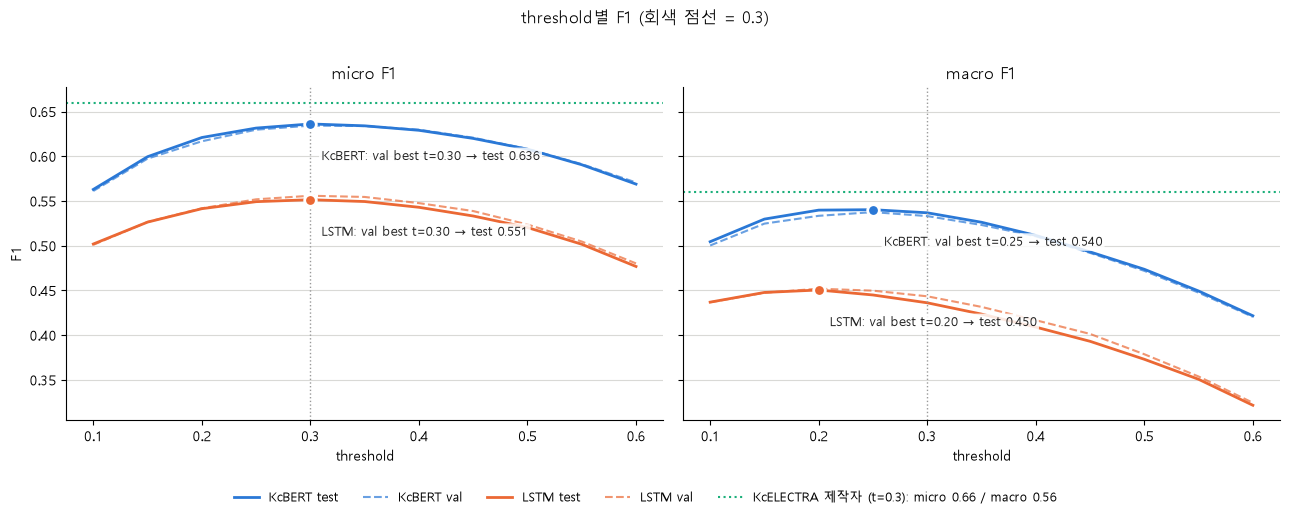

LSTM                              KcBERT                           
          val              test               val              test         
     micro_f1 macro_f1 micro_f1 macro_f1 micro_f1 macro_f1 micro_f1 macro_f1
t                                                                           
0.10   0.5010   0.4367   0.5019   0.4369   0.5612   0.5002   0.5629   0.5044
0.15   0.5266   0.4474   0.5264   0.4477   0.5974   0.5247   0.5995   0.5298
0.20   0.5418   0.4519   0.5414   0.4505   0.6167   0.5334   0.6210   0.5398
0.25   0.5519   0.4497   0.5492   0.4449   0.6297   0.5375   0.6315   0.5403
0.30   0.5559   0.4434   0.5514   0.4362   0.6343   0.5331   0.6361   0.5368
0.35   0.5545   0.4316   0.5494   0.4235   0.6338   0.5232   0.6340   0.5262
0.40   0.5476   0.4167   0.5429   0.4090   0.6297   0.5105   0.6290   0.5115
0.45   0.5387   0.4014   0.5332   0.3931   0.6207   0.4919   0.6199   0.4931
0.50   0.5237   0.3787   0.5203   0.3730   0.6082   0.4719   0.6079   0.4736
0.55   0.5047   0.3538   0.5016   0.3507   0.5912   0.4475   0.5905   0.4494
0.60   0.4802   0.3244   0.4768   0.3216   0.5707   0.4205   0.5689   0.4217

In [5]:
curve = {m: {split: pd.DataFrame([{"t": t, **scores(probs[m][split], y_val if split == "val" else y_test, t)}
                                  for t in THRESHOLDS]).set_index("t")
             for split in ("val", "test")} for m in probs}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, metric, title in [(axes[0], "micro_f1", "micro F1"), (axes[1], "macro_f1", "macro F1")]:
    for m, c in [("KcBERT", C_BERT), ("LSTM", C_LSTM)]:
        ax.plot(THRESHOLDS, curve[m]["test"][metric], color=c, lw=2, label=f"{m} test")
        ax.plot(THRESHOLDS, curve[m]["val"][metric], color=c, lw=1.5, ls="--", alpha=0.7, label=f"{m} val")
        t = best_th[m][metric]
        v = curve[m]["test"].loc[t, metric]
        ax.scatter([t], [v], s=70, color=c, edgecolor="white", linewidth=2, zorder=5)
        ax.annotate(f"{m}: val best t={t:.2f} → test {v:.3f}", (t, v), textcoords="offset points",
                    xytext=(8, -26), fontsize=9, color="#222222",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    if metric == "macro_f1":
        ax.axhline(0.56, color=C_ELEC, lw=1.5, ls=":", label="KcELECTRA 제작자 (t=0.3): micro 0.66 / macro 0.56")
    else:
        ax.axhline(0.66, color=C_ELEC, lw=1.5, ls=":")
    ax.axvline(0.3, color="#999999", lw=1, ls=":")
    ax.set_title(title)
    ax.set_xlabel("threshold")
    ax.grid(axis="y", **GRID)
axes[0].set_ylabel("F1")
handles, labels_ = axes[1].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=5, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("threshold별 F1 (회색 점선 = 0.3)", y=1.02)
plt.tight_layout()
savefig(fig, "threshold_f1.png")
plt.show()

th_table = pd.concat({(m, s): curve[m][s][["micro_f1", "macro_f1"]] for m in curve for s in ("val", "test")}, axis=1)
display(th_table.round(4))

> **해석**
>
> 점선(val)과 실선(test)이 거의 겹친다.
> val에서 고른 threshold가 test에서도 같은 성능을 내므로, val에 과적합된 선택이 아니다.
>
> micro F1이 가장 높은 threshold는 두 모델 모두 0.3이지만, macro F1은 더 낮은 쪽(LSTM 0.20, KcBERT 0.25)에서 가장 높다.
> macro F1은 44개 감정을 같은 비중으로 평균하는데, 희귀 감정은 정답이어도 예측 확률이 낮게 나오기 때문에 threshold를 낮출수록 이득을 본다.
>
> KcBERT 곡선은 0.20~0.30에서 macro 0.537~0.540으로 평평한 반면, LSTM은 0.436~0.451로 더 크게 움직인다.
> 즉 KcBERT가 threshold에 덜 민감하다. 또 0.1~0.6 **모든 threshold에서 KcBERT가 LSTM보다 위**에 있어, 어떤 threshold를 쓰더라도 두 모델의 순위는 바뀌지 않는다.

## 감정별 분석 (test, threshold 0.3)

- 세 모델을 같은 조건으로 놓기 위해 threshold 0.3으로 통일 (KcELECTRA 감정별 값도 0.3 기준)
- 빈도: train에서 그 감정이 붙은 댓글 비율

In [6]:
def per_label_f1(prob, y, t=0.3):
    pred = (prob >= t).astype(int)
    return f1_score(y, pred, average=None, zero_division=0)

# 제작자 KcELECTRA classification_report의 감정별 F1 (소수점 둘째 자리, LABELS 순서)
ELECTRA_F1 = [0.84,0.66,0.76,0.51,0.62,0.61,0.79,0.59,0.68,0.47,0.77,0.46,0.69,0.49,0.48,0.66,0.63,0.11,0.35,0.46,
              0.71,0.55,0.81,0.78,0.56,0.30,0.29,0.48,0.76,0.55,0.00,0.71,0.61,0.62,0.47,0.36,0.37,0.59,0.56,0.59,
              0.66,0.58,0.73,0.62]

lab = pd.DataFrame({
    "train_cnt": y_train.sum(0),
    "train_ratio": y_train.mean(0),
    "test_support": y_test.sum(0),
    "F1_LSTM": per_label_f1(probs["LSTM"]["test"], y_test),
    "F1_KcBERT": per_label_f1(probs["KcBERT"]["test"], y_test),
    "F1_KcELECTRA": ELECTRA_F1,
}, index=LABELS)
lab["diff"] = lab["F1_KcBERT"] - lab["F1_LSTM"]
lab = lab.sort_values("train_cnt", ascending=False)
print("macro F1 검산:", lab[["F1_LSTM", "F1_KcBERT", "F1_KcELECTRA"]].mean().round(4).to_dict())
display(lab.round(3))

macro F1 검산: {'F1_LSTM': 0.4362, 'F1_KcBERT': 0.5368, 'F1_KcELECTRA': 0.5657}


,train_cnt,train_ratio,test_support,F1_LSTM,F1_KcBERT,F1_KcELECTRA,diff
안타까움/실망,17465,0.437,2185,0.704,0.749,0.77,0.045
불평/불만,16696,0.417,2113,0.749,0.810,0.84,0.062
어이없음,15996,0.400,2055,0.704,0.757,0.78,0.053
짜증,14930,0.373,1909,0.723,0.790,0.81,0.067
화남/분노,12299,0.307,1538,0.692,0.764,0.79,0.071
한심함,12201,0.305,1519,0.618,0.686,0.71,0.068
의심/불신,11565,0.289,1539,0.611,0.682,0.69,0.071
기대감,11197,0.280,1359,0.586,0.666,0.68,0.080
즐거움/신남,10867,0.272,1321,0.675,0.750,0.76,0.075
감동/감탄,10778,0.269,1323,0.647,0.728,0.76,0.081


저장: results\per_label_f1.png


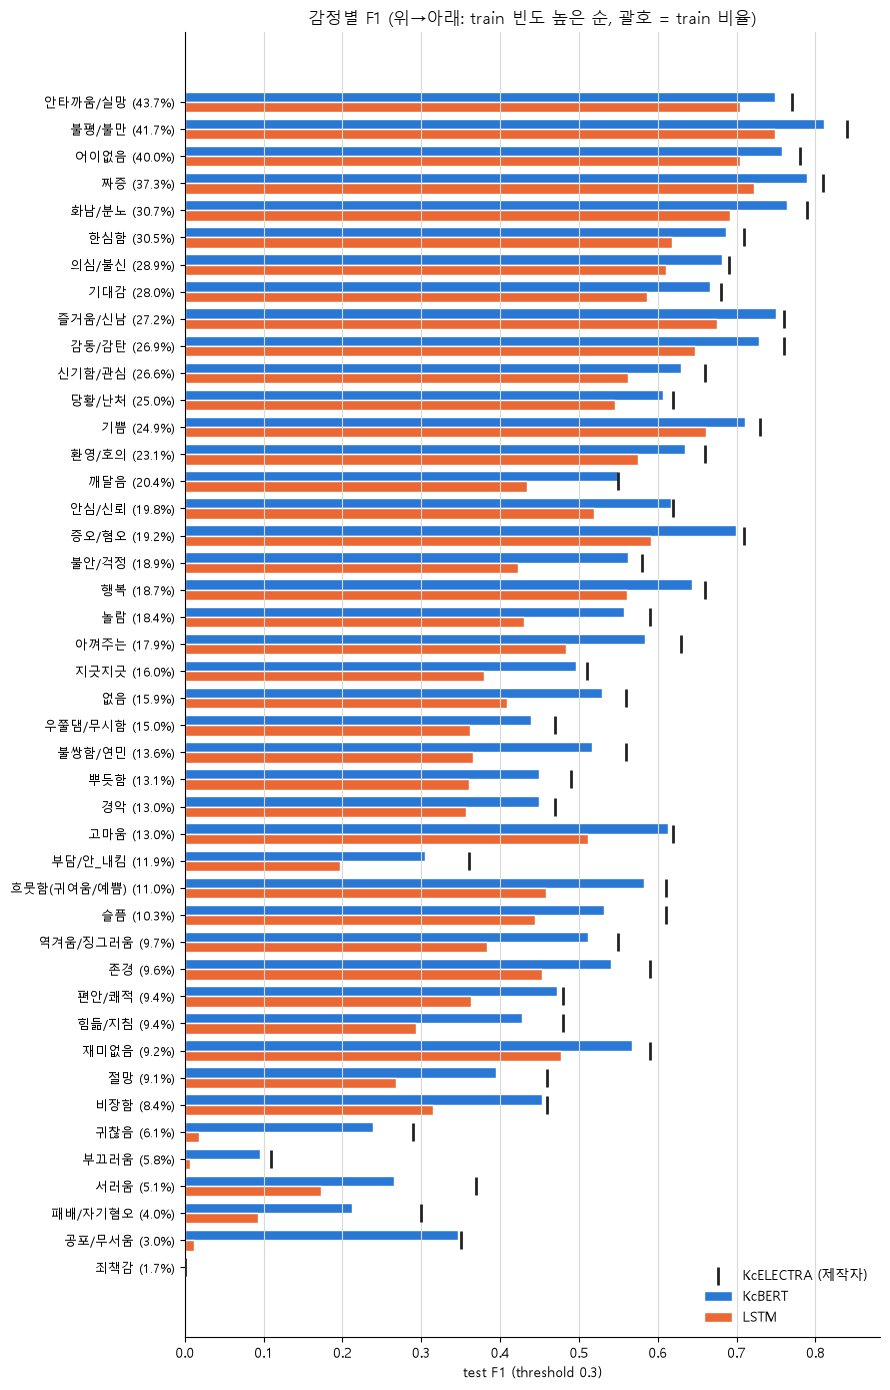

In [7]:
fig, ax = plt.subplots(figsize=(9, 14))
yy = np.arange(len(lab))
h = 0.38
ax.barh(yy - h / 2, lab["F1_KcBERT"], height=h, color=C_BERT, label="KcBERT", edgecolor="white", linewidth=1)
ax.barh(yy + h / 2, lab["F1_LSTM"], height=h, color=C_LSTM, label="LSTM", edgecolor="white", linewidth=1)
ax.scatter(lab["F1_KcELECTRA"], yy, marker="|", s=160, color="#222222", linewidth=2, label="KcELECTRA (제작자)", zorder=5)
ax.set_yticks(yy)
ax.set_yticklabels([f"{n} ({r:.1%})" for n, r in zip(lab.index, lab["train_ratio"])], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("test F1 (threshold 0.3)")
ax.set_title("감정별 F1 (위→아래: train 빈도 높은 순, 괄호 = train 비율)")
ax.grid(axis="x", **GRID)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
savefig(fig, "per_label_f1.png")
plt.show()

저장: results\freq_vs_f1.png


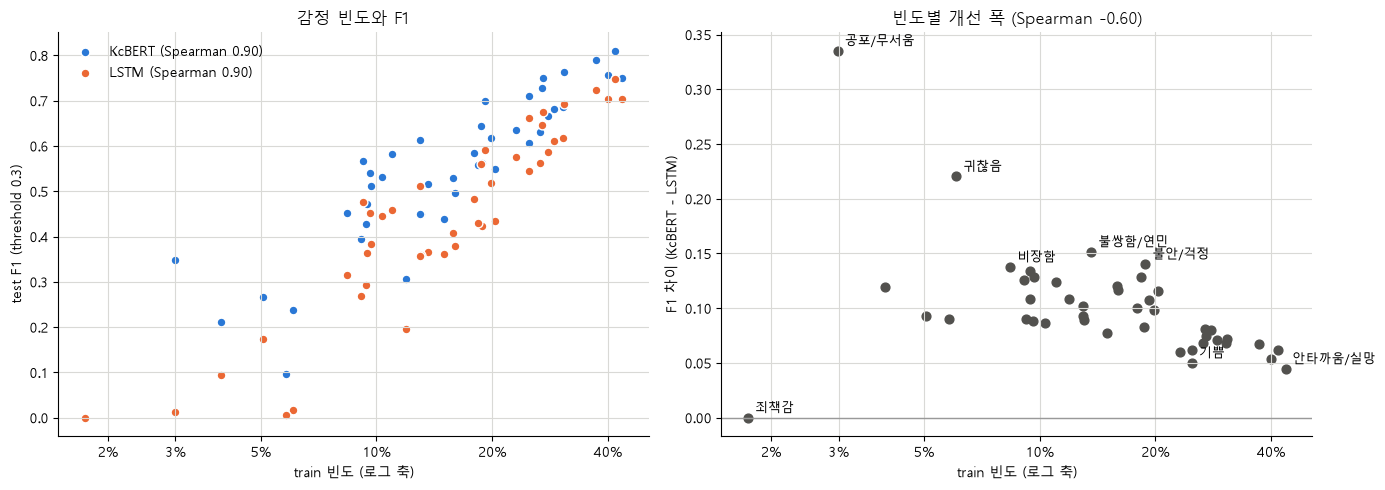

,감정 수,F1_LSTM,F1_KcBERT,F1_KcELECTRA,diff,KcBERT/LSTM 비율
빈도 구간,,,,,,
5% 미만,3,0.035,0.186,0.217,0.151,5.327
5~10%,10,0.275,0.397,0.438,0.122,1.442
10~20%,16,0.428,0.536,0.566,0.108,1.252
20% 이상,15,0.632,0.701,0.721,0.069,1.108


Spearman(train 빈도, F1_LSTM) = 0.904
Spearman(train 빈도, F1_KcBERT) = 0.899
Spearman(train 빈도, 차이) = -0.599


In [8]:
from scipy.stats import spearmanr

from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter
def log_axis(ax):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([2, 3, 5, 10, 20, 40]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
    ax.set_xlabel("train 빈도 (로그 축)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for m, c in [("KcBERT", C_BERT), ("LSTM", C_LSTM)]:
    ax.scatter(lab["train_ratio"] * 100, lab[f"F1_{m}"], s=40, color=c, edgecolor="white", linewidth=1,
               label=f"{m} (Spearman {spearmanr(lab['train_ratio'], lab[f'F1_{m}'])[0]:.2f})")
log_axis(ax)
ax.set_ylabel("test F1 (threshold 0.3)")
ax.set_title("감정 빈도와 F1")
ax.grid(**GRID)
ax.legend(frameon=False)

ax = axes[1]
ax.axhline(0, color="#999999", lw=1)
ax.scatter(lab["train_ratio"] * 100, lab["diff"], s=40, color="#52514e")
to_label = list(lab["diff"].nlargest(5).index) + list(lab["diff"].nsmallest(3).index)
for name in to_label:
    r = lab.loc[name]
    ax.annotate(name, (r["train_ratio"] * 100, r["diff"]), fontsize=9, xytext=(5, 4), textcoords="offset points")
log_axis(ax)
ax.set_ylabel("F1 차이 (KcBERT - LSTM)")
ax.set_title(f"빈도별 개선 폭 (Spearman {spearmanr(lab['train_ratio'], lab['diff'])[0]:.2f})")
ax.grid(**GRID)
plt.tight_layout()
savefig(fig, "freq_vs_f1.png")
plt.show()

# 빈도 구간별 평균 F1
lab["빈도 구간"] = pd.cut(lab["train_ratio"], bins=[0, 0.05, 0.10, 0.20, 1.0],
                       labels=["5% 미만", "5~10%", "10~20%", "20% 이상"])
grp = lab.groupby("빈도 구간", observed=True)[["F1_LSTM", "F1_KcBERT", "F1_KcELECTRA", "diff"]].agg("mean")
grp.insert(0, "감정 수", lab.groupby("빈도 구간", observed=True).size())
grp["KcBERT/LSTM 비율"] = grp["F1_KcBERT"] / grp["F1_LSTM"]
display(grp.round(3))
for m in ("LSTM", "KcBERT"):
    print(f"Spearman(train 빈도, F1_{m}) = {spearmanr(lab['train_ratio'], lab[f'F1_{m}'])[0]:.3f}")
print(f"Spearman(train 빈도, 차이) = {spearmanr(lab['train_ratio'], lab['diff'])[0]:.3f}")

In [9]:
cols = ["train_ratio", "test_support", "F1_LSTM", "F1_KcBERT", "diff", "F1_KcELECTRA"]
print("KcBERT가 LSTM보다 가장 크게 나아진 감정 5개")
display(lab.sort_values("diff", ascending=False)[cols].head(5).round(3))
print("차이가 가장 작거나 나빠진 감정 5개")
display(lab.sort_values("diff")[cols].head(5).round(3))
print("KcBERT가 LSTM보다 낮은 감정 수:", int((lab["diff"] < 0).sum()), "/ 44")

KcBERT가 LSTM보다 가장 크게 나아진 감정 5개


,train_ratio,test_support,F1_LSTM,F1_KcBERT,diff,F1_KcELECTRA
공포/무서움,0.030,164,0.012,0.347,0.335,0.35
귀찮음,0.061,290,0.018,0.238,0.220,0.29
불쌍함/연민,0.136,685,0.365,0.517,0.152,0.56
불안/걱정,0.189,960,0.423,0.563,0.140,0.58
비장함,0.084,416,0.315,0.453,0.138,0.46


차이가 가장 작거나 나빠진 감정 5개


,train_ratio,test_support,F1_LSTM,F1_KcBERT,diff,F1_KcELECTRA
죄책감,0.017,84,0.000,0.000,0.000,0.00
안타까움/실망,0.437,2185,0.704,0.749,0.045,0.77
기쁨,0.249,1205,0.661,0.711,0.050,0.73
어이없음,0.400,2055,0.704,0.757,0.053,0.78
환영/호의,0.231,1109,0.575,0.634,0.060,0.66


KcBERT가 LSTM보다 낮은 감정 수: 0 / 44


> **해석**
>
> 44개 감정 모두에서 KcBERT의 F1이 LSTM 이상이다. LSTM보다 낮은 감정은 하나도 없고, 죄책감만 두 모델 모두 0.000으로 같다.
>
> 감정 빈도와 F1의 순위 상관(Spearman)은 두 모델 모두 0.90으로 강하다. 사전학습 모델을 써도 **많이 나온 감정은 잘 맞히고 드문 감정은 못 맞히는 구조 자체는 그대로**다.
>
> 다만 드문 감정에서 무너지는 정도는 LSTM이 훨씬 심하다. train 비율 5% 미만 감정의 평균 F1은 LSTM 0.035, KcBERT 0.186이며, LSTM은 귀찮음(0.018), 부끄러움(0.006), 공포/무서움(0.012)을 사실상 하나도 맞히지 못한다. 빈도와 개선 폭의 Spearman 상관이 -0.60이고, 빈도 구간별 평균 개선 폭도 +0.151 / +0.122 / +0.108 / +0.069로 줄어든다.
> **드문 감정일수록 KcBERT로 바꿨을 때 얻는 이득이 크다.**
>
> 가장 많이 좋아진 감정은 공포/무서움(+0.335), 귀찮음(+0.220), 불쌍함/연민(+0.152), 불안/걱정(+0.140), 비장함(+0.138)이다.
> 반대로 개선 폭이 작은 감정은 죄책감(0.000, 세 모델 모두 0)을 빼면 안타까움/실망(+0.045), 기쁨(+0.050), 어이없음(+0.053), 환영/호의(+0.060)로, 모두 train 비율 23% 이상인 흔한 감정이고 LSTM도 이미 0.57~0.70을 내던 감정이다.
> 흔한 감정은 특정 단어만 보고도 어느 정도 맞힐 수 있어서 개선 여지가 작았던 것으로 보인다. 과제 1에서 단어 순서를 보지 않는 임베딩 평균 모델이 LSTM과 비슷한 성능을 냈던 결과와도 맞는다.
>
> KcELECTRA와의 차이(반올림 값 기준)는 5% 미만 0.031, 5~10% 0.041, 10~20% 0.030, 20% 이상 0.020으로, 흔한 감정 구간에서 가장 작다.

## 오류 사례 분석 (test, threshold 0.3)

- 댓글별 F1 = 2 × (맞힌 감정 수) / (정답 감정 수 + 예측 감정 수) — 과제 1 노트북의 `sample_f1`과 같은 정의
- 구간별 성능은 micro F1(구간 안의 모든 감정 판단을 합쳐 계산)과 댓글 F1 평균을 함께 표시

In [10]:
def sample_f1(true, pred):
    overlap = (true * pred).sum(axis=1)
    denom = true.sum(axis=1) + pred.sum(axis=1)
    return np.where(denom > 0, 2 * overlap / np.maximum(denom, 1), 1.0)

pred = {m: (probs[m]["test"] >= 0.3).astype(int) for m in probs}
res = test_df[["text"]].copy()
res["char_len"] = res["text"].str.len()
for m in probs:
    res[f"f1_{m}"] = sample_f1(y_test, pred[m])
res["diff"] = res["f1_KcBERT"] - res["f1_LSTM"]

print("댓글 F1 평균:", res[["f1_LSTM", "f1_KcBERT"]].mean().round(3).to_dict())
print(f"KcBERT가 더 높은 댓글 {(res['diff'] > 0).mean():.1%} | 같음 {(res['diff'] == 0).mean():.1%} | LSTM이 더 높음 {(res['diff'] < 0).mean():.1%}")

def group_report(mask_dict):
    rows = []
    for name, mask in mask_dict.items():
        mask = np.asarray(mask)
        r = {"구간": name, "댓글 수": int(mask.sum())}
        if mask.sum() == 0:   # 해당 댓글이 없는 구간
            rows.append(r)
            continue
        for m in probs:
            r[f"microF1_{m}"] = f1_score(y_test[mask], pred[m][mask], average="micro", zero_division=0)
        r["micro 차이"] = r["microF1_KcBERT"] - r["microF1_LSTM"]
        for m in probs:
            r[f"댓글F1_{m}"] = res.loc[mask, f"f1_{m}"].mean()
        r["평균 글자 수"] = res.loc[mask, "char_len"].mean()
        rows.append(r)
    return pd.DataFrame(rows).set_index("구간")

def show(i):
    t = set(np.where(y_test[i])[0])
    print(f"[{i}] {res.loc[i, 'text']}")
    print("   정답  :", [LABELS[j] for j in sorted(t)])
    for m in ("LSTM", "KcBERT"):
        p = set(np.where(pred[m][i])[0])
        print(f"   {m:6} F1 {res.loc[i, f'f1_{m}']:.2f} | 맞춤 {len(t & p)} | 놓침 {[LABELS[j] for j in sorted(t - p)]} | 오답 {[LABELS[j] for j in sorted(p - t)]}")
    print()

댓글 F1 평균: {'f1_LSTM': 0.539, 'f1_KcBERT': 0.626}
KcBERT가 더 높은 댓글 63.8% | 같음 9.6% | LSTM이 더 높음 26.7%


### LSTM은 틀리고 KcBERT는 맞힌 댓글 / 반대 경우

In [11]:
# 한쪽 댓글 F1 >= 0.7, 다른 쪽 <= 0.3 인 댓글 중 차이가 큰 순 (같으면 짧은 댓글 우선)
a = res[(res["f1_KcBERT"] >= 0.7) & (res["f1_LSTM"] <= 0.3)]
b = res[(res["f1_LSTM"] >= 0.7) & (res["f1_KcBERT"] <= 0.3)]
print(f"LSTM 틀림 & KcBERT 맞힘: {len(a)}개 | KcBERT 틀림 & LSTM 맞힘: {len(b)}개\n")
print("=== LSTM은 틀리고 KcBERT는 맞힌 댓글 ===\n")
for i in a.assign(L=a["char_len"]).sort_values(["diff", "L"], ascending=[False, True]).index[:5]:
    show(i)

LSTM 틀림 & KcBERT 맞힘: 109개 | KcBERT 틀림 & LSTM 맞힘: 7개

=== LSTM은 틀리고 KcBERT는 맞힌 댓글 ===

[1548] 모든걸 열심히 하는 호중님 ~~~ 버릴게하나도없어요~
   정답  : ['환영/호의', '감동/감탄', '고마움', '존경', '기대감', '신기함/관심', '아껴주는', '즐거움/신남', '행복', '기쁨', '안심/신뢰']
   LSTM   F1 0.00 | 맞춤 0 | 놓침 ['환영/호의', '감동/감탄', '고마움', '존경', '기대감', '신기함/관심', '아껴주는', '즐거움/신남', '행복', '기쁨', '안심/신뢰'] | 오답 ['불평/불만', '안타까움/실망', '한심함', '짜증', '어이없음', '힘듦/지침', '당황/난처', '부담/안_내킴', '불쌍함/연민', '불안/걱정']
   KcBERT F1 0.92 | 맞춤 11 | 놓침 [] | 오답 ['뿌듯함', '흐뭇함(귀여움/예쁨)']

[4087] 또 물타기 한다! 시험  컨닝한 학생이 다른 학생도 컨닝 했으니 괜찮다?
   정답  : ['불평/불만', '지긋지긋', '화남/분노', '안타까움/실망', '의심/불신', '절망', '한심함', '짜증', '어이없음', '증오/혐오', '당황/난처']
   LSTM   F1 0.00 | 맞춤 0 | 놓침 ['불평/불만', '지긋지긋', '화남/분노', '안타까움/실망', '의심/불신', '절망', '한심함', '짜증', '어이없음', '증오/혐오', '당황/난처'] | 오답 ['환영/호의', '감동/감탄', '기대감', '뿌듯함', '신기함/관심', '없음', '즐거움/신남', '깨달음', '놀람', '기쁨', '안심/신뢰']
   KcBERT F1 0.90 | 맞춤 9 | 놓침 ['절망', '당황/난처'] | 오답 []

[4734] 강바닥에 쏟아부었던 22조는 이명박 사재였더냐
   정답  : ['불평/불만', '지긋지긋', '화남/분노', '안타까움/실망', '의심/불신

In [12]:
print("=== KcBERT는 틀리고 LSTM은 맞힌 댓글 ===\n")
for i in b.assign(L=b["char_len"]).sort_values(["diff", "L"], ascending=[True, True]).index[:5]:
    show(i)

=== KcBERT는 틀리고 LSTM은 맞힌 댓글 ===

[1167] 정신못차렸나봐요ㅜ살인미수예요ㅡㅡ제발음주운전하지마세요
   정답  : ['불평/불만', '지긋지긋', '화남/분노', '안타까움/실망', '비장함', '공포/무서움', '한심함', '역겨움/징그러움', '짜증', '어이없음', '증오/혐오', '경악', '불안/걱정']
   LSTM   F1 0.77 | 맞춤 10 | 놓침 ['비장함', '공포/무서움', '불안/걱정'] | 오답 ['의심/불신', '절망', '당황/난처']
   KcBERT F1 0.10 | 맞춤 1 | 놓침 ['불평/불만', '지긋지긋', '화남/분노', '비장함', '공포/무서움', '한심함', '역겨움/징그러움', '짜증', '어이없음', '증오/혐오', '경악', '불안/걱정'] | 오답 ['감동/감탄', '슬픔', '즐거움/신남', '흐뭇함(귀여움/예쁨)', '행복', '기쁨']

[4887] 그런가 그래도 송중기는 확실히 연기 잘하던데 전여빈은 조금 아쉽고
   정답  : ['환영/호의', '감동/감탄', '존경', '기대감', '안타까움/실망', '신기함/관심', '아껴주는', '깨달음', '안심/신뢰']
   LSTM   F1 0.82 | 맞춤 7 | 놓침 ['존경', '아껴주는'] | 오답 ['불평/불만']
   KcBERT F1 0.17 | 맞춤 1 | 놓침 ['환영/호의', '감동/감탄', '존경', '기대감', '신기함/관심', '아껴주는', '깨달음', '안심/신뢰'] | 오답 ['불평/불만', '불쌍함/연민']

[1414] 이 정도면 나스 아니냐구...
   정답  : ['불평/불만', '화남/분노', '안타까움/실망', '의심/불신', '절망', '한심함', '짜증', '어이없음', '없음', '힘듦/지침', '증오/혐오', '당황/난처', '불안/걱정']
   LSTM   F1 0.75 | 맞춤 9 | 놓침 ['절망', '없음', '힘듦/지침', '불안/걱정'] | 오답 ['우쭐댐/무시함', '

> **해석**
>
> 댓글 단위로 보면 KcBERT가 더 높은 댓글이 63.8%, 같은 댓글이 9.6%, LSTM이 더 높은 댓글이 26.7%다. 한쪽만 크게 맞힌 경우(댓글 F1 ≥ 0.7 vs ≤ 0.3)는 KcBERT 쪽 109개, LSTM 쪽 7개로 차이가 뚜렷하다.
>
> LSTM이 틀린 사례는 대부분 **극성 자체를 반대로 예측**한 경우다.
> 칭찬 댓글(1548)에는 부정 감정을 10개 붙였고, 비꼬는 댓글(4087 "컨닝 했으니 괜찮다?", 4734 "이명박 사재였더냐")에는 긍정 감정을 11개 붙였다. 반어나 수사 의문문은 단어만 보면 중립이나 긍정에 가까워서, 문장 전체의 뉘앙스를 읽어야 맞힐 수 있는 경우다.
>
> KcBERT가 틀린 사례 중 1167은 `ㅜ`, `ㅡㅡ`가 들어 있고 띄어쓰기가 없는 댓글로, KcBERT에서 [UNK]가 되는 표현을 포함한다(아래 '신조어 · 오탈자 · 이모티콘 댓글' 참고). 나머지 사례(4887, 1414, 2778, 1351)에서는 뚜렷한 공통점을 찾지 못했다.

### 부정어가 들어간 댓글

- MeCab 품사로 판별 (글자만 찾으면 '안'(내부), '없음'(라벨 이름 같은 명사) 등이 섞임)
    - 안/못: 부사(MAG), 않/못하: 보조용언(VX), 없: 형용사(VA)
- LSTM의 긍정/부정 감정 묶음으로 **극성 뒤집힘**(정답은 부정 우세인데 예측은 긍정 우세, 또는 반대) 비율도 함께 확인

In [13]:
from mecab import MeCab
mecab = MeCab()
test_pos = [mecab.pos(t) for t in res["text"]]
test_morphs = [[w for w, _ in p] for p in test_pos]

NEG_RULES = {"안": {"MAG"}, "못": {"MAG", "VX"}, "않": {"VX"}, "없": {"VA"}}
def neg_words(pos):
    found = set()
    for w, tag in pos:
        head = tag.split("+")[0]
        for k, tags in NEG_RULES.items():
            if w.startswith(k) and head in tags:
                found.add(k)
    return found

res["neg"] = [neg_words(p) for p in test_pos]
res["has_neg"] = res["neg"].str.len() > 0

POS = ['환영/호의','감동/감탄','고마움','존경','기대감','뿌듯함','편안/쾌적','신기함/관심',
       '아껴주는','즐거움/신남','흐뭇함(귀여움/예쁨)','행복','기쁨','안심/신뢰']
NEG = ['불평/불만','지긋지긋','슬픔','화남/분노','우쭐댐/무시함','안타까움/실망','의심/불신',
       '부끄러움','공포/무서움','절망','한심함','역겨움/징그러움','짜증','어이없음',
       '패배/자기혐오','귀찮음','힘듦/지침','죄책감','증오/혐오','당황/난처','부담/안_내킴',
       '서러움','재미없음','불쌍함/연민','불안/걱정']
pi, ni = [LABELS.index(l) for l in POS], [LABELS.index(l) for l in NEG]
polarity = lambda y: np.sign(y[:, pi].sum(1) - y[:, ni].sum(1))
for m in probs:
    res[f"flip_{m}"] = (polarity(y_test) * polarity(pred[m])) == -1

masks = {"부정어 없음": ~res["has_neg"], "부정어 있음": res["has_neg"]}
for k in NEG_RULES:
    masks[f"  '{k}' 포함"] = res["neg"].apply(lambda s: k in s)
neg_df = group_report(masks)
for m in probs:
    neg_df[f"극성뒤집힘_{m}"] = [res.loc[np.asarray(mk), f"flip_{m}"].mean() for mk in masks.values()]
display(neg_df.round(3))
print("전체 test 극성 뒤집힘 비율:", {m: round(float(res[f"flip_{m}"].mean()), 4) for m in probs})

,댓글 수,microF1_LSTM,microF1_KcBERT,micro 차이,댓글F1_LSTM,댓글F1_KcBERT,평균 글자 수,극성뒤집힘_LSTM,극성뒤집힘_KcBERT
구간,,,,,,,,,
부정어 없음,3567,0.543,0.631,0.087,0.530,0.618,46.081,0.162,0.099
부정어 있음,1433,0.571,0.649,0.078,0.564,0.645,85.076,0.127,0.083
'안' 포함,605,0.579,0.657,0.079,0.572,0.656,90.064,0.114,0.074
'못' 포함,289,0.582,0.645,0.062,0.575,0.641,90.882,0.111,0.059
'않' 포함,319,0.552,0.644,0.091,0.552,0.641,106.063,0.154,0.116
'없' 포함,526,0.586,0.669,0.083,0.581,0.664,93.447,0.133,0.078


전체 test 극성 뒤집힘 비율: {'LSTM': 0.152, 'KcBERT': 0.0942}


In [ ]:
# 부정어가 있으면서 LSTM은 극성을 뒤집고 KcBERT는 맞힌 댓글 예시
ex = res[res["has_neg"] & res["flip_LSTM"] & ~res["flip_KcBERT"]].sort_values("char_len")
print(f"부정어 있음 & LSTM만 극성 뒤집힘: {len(ex)}개 | 반대(KcBERT만 뒤집힘): {int((res['has_neg'] & ~res['flip_LSTM'] & res['flip_KcBERT']).sum())}개\n")
for i in ex.index[:4]:
    show(i)

부정어 있음 & LSTM만 극성 뒤집힘: 119개 | 반대(KcBERT만 뒤집힘): 56개

[4449] 안하더라구욬ㅋㅋㅋㅋ
   정답  : ['안타까움/실망', '한심함', '어이없음', '없음', '즐거움/신남', '깨달음', '당황/난처', '서러움']
   LSTM   F1 0.40 | 맞춤 3 | 놓침 ['안타까움/실망', '한심함', '어이없음', '깨달음', '서러움'] | 오답 ['기대감', '신기함/관심', '흐뭇함(귀여움/예쁨)', '놀람']
   KcBERT F1 0.67 | 맞춤 6 | 놓침 ['안타까움/실망', '서러움'] | 오답 ['우쭐댐/무시함', '신기함/관심', '귀찮음', '기쁨']

[2753] 안아파 걱정마로~~
   정답  : ['고마움', '신기함/관심', '아껴주는', '힘듦/지침', '즐거움/신남', '불쌍함/연민', '불안/걱정', '안심/신뢰']
   LSTM   F1 0.53 | 맞춤 4 | 놓침 ['고마움', '신기함/관심', '즐거움/신남', '안심/신뢰'] | 오답 ['슬픔', '기대감', '안타까움/실망']
   KcBERT F1 0.46 | 맞춤 3 | 놓침 ['고마움', '신기함/관심', '힘듦/지침', '즐거움/신남', '불쌍함/연민'] | 오답 ['환영/호의', '기대감']

[1476] 헐크 영화 안 보셨져???????!!!
   정답  : ['안타까움/실망', '의심/불신', '신기함/관심', '어이없음', '당황/난처', '경악', '놀람']
   LSTM   F1 0.53 | 맞춤 4 | 놓침 ['안타까움/실망', '의심/불신', '경악'] | 오답 ['감동/감탄', '기대감', '즐거움/신남', '깨달음']
   KcBERT F1 0.80 | 맞춤 6 | 놓침 ['의심/불신'] | 오답 ['감동/감탄', '즐거움/신남']

[14] 박정희와 존경이란 단어는 어울릴수가 없다
   정답  : ['불평/불만', '비장함', '짜증', '어이없음', '증오/혐오', '부담/안_내킴']
   LS

> **해석**
>
> 겉으로 보면 두 모델 모두 부정어가 **있는** 댓글에서 F1이 더 높다(LSTM 0.543 → 0.571, KcBERT 0.631 → 0.649).
> 하지만 부정어 댓글은 평균 85자로 다른 댓글(46자)보다 길고, 아래 길이 분석에서 보듯 긴 댓글일수록 F1이 높아서 길이 효과가 섞여 있다. 이 부분은 '길이를 맞춰서 다시 보기'에서 다시 확인한다.
>
> KcBERT의 우위(micro 차이)는 부정어 있음 0.078, 없음 0.087로 부정어가 있을 때 오히려 약간 작다. 따라서 **이 데이터에서는 'KcBERT가 부정어를 특히 잘 처리한다'는 근거를 찾을 수 없다.**
>
> 극성 뒤집힘 비율은 KcBERT가 전반적으로 낮다(부정어 없음 16.2% → 9.9%, 있음 12.7% → 8.3%). 부정어 댓글 중 LSTM만 극성을 뒤집은 경우는 119개, KcBERT만 뒤집은 경우는 56개다. 즉 KcBERT가 극성을 덜 틀리는 효과는 부정어 유무와 관계없이 비슷하게 나타난다.

### 댓글 길이 구간별 성능

- 구간은 모델과 무관하게 **원문 글자 수**로 나눔
- 잘림: LSTM은 형태소 80개 초과, KcBERT는 clean 후 토큰 128개 초과일 때 앞/뒤가 잘림

D:\haewoon\KDT\12_NLP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


잘린 test 댓글 - LSTM(형태소>80): 206 | KcBERT(토큰>128): 15


,댓글 수,microF1_LSTM,microF1_KcBERT,micro 차이,댓글F1_LSTM,댓글F1_KcBERT,평균 글자 수,LSTM 잘림 비율
구간,,,,,,,,
~20자,418,0.515,0.580,0.065,0.504,0.570,15.411,0.000
21~50자,2589,0.534,0.622,0.088,0.521,0.612,33.362,0.000
51~100자,1321,0.567,0.653,0.086,0.553,0.644,70.342,0.000
101~200자,565,0.591,0.676,0.084,0.587,0.668,131.494,0.175
201자~,107,0.681,0.723,0.042,0.689,0.734,245.355,1.000


저장: results\length_bins_f1.png


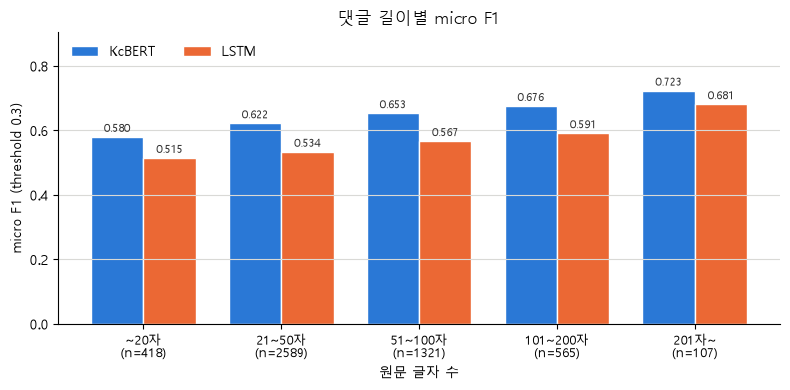

In [15]:
from transformers import AutoTokenizer
import emoji
from soynlp.normalizer import repeat_normalize

# 02_kcbert_finetuning.ipynb와 같은 clean 함수
emojis = "".join(emoji.EMOJI_DATA.keys())
pattern = re.compile(f"[^ .,?!/@$%~％·∼()\x00-\x7Fㄱ-ㅣ가-힣{emojis}]+")
url_pattern = re.compile(r"https?:\/\/(www\.)?[-a-zA-Z0-9@:%._\+~#=]{1,256}\.[a-zA-Z0-9()]{1,6}\b([-a-zA-Z0-9()@:%_\+.~#?&//=]*)")
def clean(x):
    x = pattern.sub(" ", x)
    x = emoji.replace_emoji(x, replace="")
    x = url_pattern.sub("", x)
    x = x.strip()
    return repeat_normalize(x, num_repeats=2)

tok = AutoTokenizer.from_pretrained("beomi/kcbert-base")
bert_ids = tok([clean(t) for t in res["text"]], add_special_tokens=True)["input_ids"]
res["bert_len"] = [len(x) for x in bert_ids]
res["bert_unk"] = [x.count(tok.unk_token_id) for x in bert_ids]
res["morph_len"] = [len(m) for m in test_morphs]
print("잘린 test 댓글 - LSTM(형태소>80):", int((res["morph_len"] > 80).sum()), "| KcBERT(토큰>128):", int((res["bert_len"] > 128).sum()))

len_bins = pd.cut(res["char_len"], bins=[0, 20, 50, 100, 200, 1000], labels=["~20자", "21~50자", "51~100자", "101~200자", "201자~"])
len_df = group_report({b: (len_bins == b).values for b in len_bins.cat.categories})
len_df["LSTM 잘림 비율"] = [(res.loc[(len_bins == b).values, "morph_len"] > 80).mean() for b in len_bins.cat.categories]
display(len_df.round(3))

def bar_by_group(df, title, fname, xlabel):
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(df))
    w = 0.38
    for k, (m, c) in enumerate([("KcBERT", C_BERT), ("LSTM", C_LSTM)]):
        bars = ax.bar(x + (k - 0.5) * w, df[f"microF1_{m}"], width=w, color=c, label=m, edgecolor="white", linewidth=1)
        ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2, color="#333333")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(df.index, df["댓글 수"])], fontsize=9)
    ax.set_ylabel("micro F1 (threshold 0.3)")
    ax.set_xlabel(xlabel)
    ax.set_ylim(0, max(df["microF1_KcBERT"].max(), df["microF1_LSTM"].max()) * 1.25)
    ax.set_title(title)
    ax.grid(axis="y", **GRID)
    ax.legend(frameon=False, loc="upper left", ncol=2)
    plt.tight_layout()
    savefig(fig, fname)
    plt.show()

bar_by_group(len_df, "댓글 길이별 micro F1", "length_bins_f1.png", "원문 글자 수")

> **해석**
>
> 모든 길이 구간에서 KcBERT가 높고, 두 모델 모두 댓글이 길수록 F1이 오른다.
> 긴 댓글일수록 감정 단서가 많고 정답 감정 수도 많기 때문으로 보인다
>
> KcBERT의 우위는 21~200자 구간에서 0.084~0.088로 비슷하고, 20자 이하(0.065)와 201자 이상(0.042, 107개)에서 작아진다.
>
> 201자 이상 댓글은 LSTM에서 **전부** 형태소 80개로 잘렸는데도(뒤쪽 80개만 남김) LSTM F1이 가장 높은 구간(0.681)이다.
> 이 데이터에서는 입력 잘림 때문에 성능을 크게 잃었다는 근거가 없다. KcBERT는 test에서 128토큰을 넘는 댓글이 15개뿐이므로 max_length를 늘려도 효과는 작을 것으로 예상된다.

### LSTM [UNK] 비율별 성능

- 과제 1 vocab(train 형태소 중 3회 이상, `results/lstm_vocab.json`)으로 test 댓글의 형태소를 변환해 `<UNK>` 비율 계산
- 비율 = `<UNK>` 형태소 수 / 전체 형태소 수 (자르기 전 기준)

test 전체 <UNK> 토큰 비율: 3.82% (과제 1 노트북 기록 3.82%)


,댓글 수,microF1_LSTM,microF1_KcBERT,micro 차이,댓글F1_LSTM,댓글F1_KcBERT,평균 글자 수
구간,,,,,,,
0%,2143,0.559,0.639,0.081,0.547,0.629,43.016
0~5%,1128,0.580,0.661,0.080,0.572,0.655,98.317
5~10%,1046,0.538,0.630,0.092,0.524,0.620,53.251
10% 초과,683,0.498,0.592,0.094,0.485,0.579,40.264


저장: results\unk_bins_f1.png


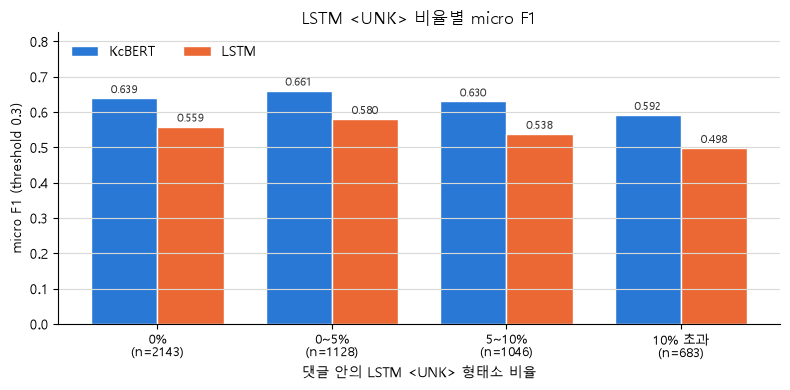

In [16]:
vocab = json.loads((RESULTS / "lstm_vocab.json").read_text(encoding="utf-8"))
res["lstm_unk"] = [sum(w not in vocab for w in ms) for ms in test_morphs]
res["lstm_unk_ratio"] = res["lstm_unk"] / res["morph_len"].clip(lower=1)
print(f"test 전체 <UNK> 토큰 비율: {res['lstm_unk'].sum() / res['morph_len'].sum():.2%} (과제 1 노트북 기록 3.82%)")

unk_bins = pd.cut(res["lstm_unk_ratio"], bins=[-0.001, 0, 0.05, 0.10, 1.0], labels=["0%", "0~5%", "5~10%", "10% 초과"])
unk_df = group_report({b: (unk_bins == b).values for b in unk_bins.cat.categories})
display(unk_df.round(3))
bar_by_group(unk_df, "LSTM <UNK> 비율별 micro F1", "unk_bins_f1.png", "댓글 안의 LSTM <UNK> 형태소 비율")

> **해석**
>
> LSTM `<UNK>` 비율이 10%를 넘는 댓글에서 LSTM micro F1은 0.559(`<UNK>` 0%) → 0.498로 떨어지지만, KcBERT도 0.639 → 0.592로 함께 떨어진다.
> 두 모델의 차이는 0.081 → 0.094로 조금 커질 뿐이다.
>
> 길이를 맞춘 비교(아래)에서도 같은 경향이 보인다. `<UNK>`가 많은 댓글은 **LSTM만이 아니라 두 모델 모두에게 어려운 댓글**(드문 주제, 고유명사가 많은 댓글)이라고 볼 수 있다. vocab 밖 단어 때문에 LSTM이 추가로 잃는 몫은 0.01~0.02 정도이고, 이런 댓글은 683개(13.7%)뿐이어서 전체 차이(0.085)에서 차지하는 비중은 작다.

### 길이를 맞춰서 다시 보기

부정어 댓글은 평균 85자로 다른 댓글(46자)보다 길고, `<UNK>` 10% 초과 댓글은 평균 40자로 짧음. 길이에 따라 F1이 달라지므로 **같은 길이 구간 안에서** 비교함

In [17]:
def stratified(flag, name):
    rows = []
    for b in len_bins.cat.categories:
        in_bin = (len_bins == b).values
        r = {"길이 구간": b}
        for lab_, mk in [(f"{name}", in_bin & flag), (f"{name} 아님", in_bin & ~flag)]:
            r[f"n ({lab_})"] = int(mk.sum())
            if mk.sum() >= 30:
                r[f"LSTM ({lab_})"] = f1_score(y_test[mk], pred["LSTM"][mk], average="micro", zero_division=0)
                r[f"KcBERT ({lab_})"] = f1_score(y_test[mk], pred["KcBERT"][mk], average="micro", zero_division=0)
                r[f"차이 ({lab_})"] = r[f"KcBERT ({lab_})"] - r[f"LSTM ({lab_})"]
        rows.append(r)
    return pd.DataFrame(rows).set_index("길이 구간")

print("부정어 있음 vs 없음 (micro F1, 구간당 30개 미만은 생략)")
display(stratified(res["has_neg"].values, "부정어").round(3))
print("LSTM <UNK> 10% 초과 vs 이하")
display(stratified((res["lstm_unk_ratio"] > 0.10).values, "UNK>10%").round(3))

부정어 있음 vs 없음 (micro F1, 구간당 30개 미만은 생략)


,n (부정어),n (부정어 아님),LSTM (부정어 아님),KcBERT (부정어 아님),차이 (부정어 아님),LSTM (부정어),KcBERT (부정어),차이 (부정어)
길이 구간,,,,,,,,
~20자,28,390,0.518,0.590,0.072,NaN,NaN,NaN
21~50자,474,2115,0.533,0.625,0.091,0.536,0.612,0.075
51~100자,507,814,0.563,0.650,0.086,0.573,0.659,0.087
101~200자,329,236,0.589,0.669,0.080,0.593,0.681,0.088
201자~,95,12,NaN,NaN,NaN,0.685,0.725,0.040


LSTM <UNK> 10% 초과 vs 이하


,n (UNK>10%),LSTM (UNK>10%),KcBERT (UNK>10%),차이 (UNK>10%),n (UNK>10% 아님),LSTM (UNK>10% 아님),KcBERT (UNK>10% 아님),차이 (UNK>10% 아님)
길이 구간,,,,,,,,
~20자,114,0.501,0.568,0.066,304,0.520,0.584,0.065
21~50자,408,0.486,0.590,0.104,2181,0.542,0.628,0.086
51~100자,130,0.523,0.616,0.093,1191,0.572,0.657,0.086
101~200자,31,0.541,0.595,0.054,534,0.594,0.680,0.086
201자~,0,NaN,NaN,NaN,107,0.681,0.723,0.042


> **해석**
>
> **부정어**: 같은 길이 구간 안에서 KcBERT 우위(부정어 있음 / 없음)는 21~50자 0.075 / 0.091, 51~100자 0.087 / 0.086, 101~200자 0.088 / 0.080으로 방향이 일정하지 않다. 부정어 유무에 따른 차이는 없다고 보는 것이 안전하다.
>
> **`<UNK>` 10% 초과**: 21~50자에서 LSTM은 0.056, KcBERT는 0.038 떨어져 LSTM이 조금 더 크게 떨어진다(우위 0.104 vs 0.086). 51~100자에서도 0.093 vs 0.086으로 같은 방향이다. 101~200자는 31개뿐이라 판단하지 않는다.

### 신조어 · 오탈자 · 이모티콘 댓글

자동으로 정확히 찾을 수 없어서 아래 **표면 패턴**으로 근사함 (오탈자는 따로 검출하지 못함 → LSTM `<UNK>` 3개 이상 댓글로 대신 확인)
- `ㅠ/ㅜ`: KcBERT vocab에 모음 자모가 없어 항상 [UNK]
- `ㅋㅋ/ㅎㅎ`: 웃음 자음
- `^^ ;; ㅡㅡ` 등 문자 이모티콘
- 유니코드 이모지 (KcBERT clean에서 제거됨)

In [18]:
emo_masks = {
    "전체": np.ones(len(res), bool),
    "ㅠ/ㅜ 포함": res["text"].str.contains("[ㅠㅜ]").values,
    "ㅋㅋ/ㅎㅎ 포함": res["text"].str.contains("[ㅋㅎ]{2,}").values,
    "^^ ;; ㅡㅡ 등": res["text"].str.contains(r"\^\^|;;|ㅡㅡ|:\)|T\.T|ㅠ\.ㅠ").values,
    "유니코드 이모지": res["text"].apply(lambda t: emoji.emoji_count(t) > 0).values,
    "KcBERT [UNK] 있음": (res["bert_unk"] > 0).values,
    "LSTM <UNK> 3개 이상": (res["lstm_unk"] >= 3).values,
}
emo_df = group_report(emo_masks)
display(emo_df.round(3))

,댓글 수,microF1_LSTM,microF1_KcBERT,micro 차이,댓글F1_LSTM,댓글F1_KcBERT,평균 글자 수
구간,,,,,,,
전체,5000,0.551,0.636,0.085,0.539,0.626,57.257
ㅠ/ㅜ 포함,395,0.524,0.594,0.069,0.515,0.584,67.691
ㅋㅋ/ㅎㅎ 포함,740,0.545,0.632,0.087,0.539,0.624,47.500
^^ ;; ㅡㅡ 등,260,0.624,0.674,0.049,0.613,0.665,77.854
유니코드 이모지,0,NaN,NaN,NaN,NaN,NaN,NaN
KcBERT [UNK] 있음,558,0.539,0.604,0.065,0.530,0.595,68.828
LSTM <UNK> 3개 이상,656,0.544,0.642,0.098,0.534,0.631,102.021


In [19]:
def show_tokens(i):
    unk_m = [w for w in test_morphs[i] if w not in vocab]
    print(f"   LSTM <UNK> 형태소: {unk_m} | KcBERT [UNK] 개수: {res.loc[i, 'bert_unk']}")
    show(i)

print("=== LSTM <UNK> 3개 이상 (신조어/오탈자 후보), 두 모델 차이가 큰 순 ===\n")
sub = res[res["lstm_unk"] >= 3].sort_values("diff", ascending=False)
for i in list(sub.index[:3]) + list(sub.index[-2:]):
    show_tokens(i)
print("=== ㅠ/ㅜ 포함 짧은 댓글 ===\n")
for i in res[emo_masks["ㅠ/ㅜ 포함"]].sort_values("char_len").index[:3]:
    show_tokens(i)

=== LSTM <UNK> 3개 이상 (신조어/오탈자 후보), 두 모델 차이가 큰 순 ===

   LSTM <UNK> 형태소: ['쥐약', '이상호', '팟캐스트', '브라우니'] | KcBERT [UNK] 개수: 0
[684] 쥐약어플에 이상호 기자의 발뉴스가 자리를 잡았군요 정식 뉴스말고도 간단한 내용들이 있네요..요즘은 팟캐스트로 모든걸 해결하는 느낌이랄까? 골라먹는 재미도 쏠쏠~~잠이 오지 않기에 밤새 빵을 구웠어요 브라우니에 커피 한잔 누구 손?1
   정답  : ['환영/호의', '감동/감탄', '고마움', '기대감', '뿌듯함', '편안/쾌적', '신기함/관심', '아껴주는', '즐거움/신남', '깨달음', '기쁨', '안심/신뢰']
   LSTM   F1 0.00 | 맞춤 0 | 놓침 ['환영/호의', '감동/감탄', '고마움', '기대감', '뿌듯함', '편안/쾌적', '신기함/관심', '아껴주는', '즐거움/신남', '깨달음', '기쁨', '안심/신뢰'] | 오답 ['불평/불만', '지긋지긋', '화남/분노', '안타까움/실망', '의심/불신', '한심함', '역겨움/징그러움', '짜증', '어이없음', '증오/혐오', '당황/난처', '경악', '불안/걱정']
   KcBERT F1 0.83 | 맞춤 10 | 놓침 ['고마움', '아껴주는'] | 오답 ['놀람', '행복']

   LSTM <UNK> 형태소: ['월권', '일으켜도', '터줏대감', '텃새', '꼴불견'] | KcBERT [UNK] 개수: 0
[4779] 그런 아줌마들은 월권? 회원권? 같은거 사서 거의 매일 출근하다시피 해서 문제 일으켜도 목욕탕에서도 별말 안하고 넘어가더라구요. 저는 가끔 목욕 가는데 갈때마다 만나는 아줌마들 몇 명 있어요. 터줏대감처럼 사우나에 앉아서 들어오는 사람 스캔하고 나가면 그사람 흉도 보고... 명절때는 텃새를 부르는건지 사우나에서 다른 사람들이랑 싸우고 꼴불견 입니다.
   정답  : ['불평/불만', '지긋지긋', '화남/분노', '안타까

> **해석**
>
> 유니코드 이모지는 KOTE test에 하나도 없어서 이모지의 영향은 이 데이터로 평가할 수 없다.
>
> KcBERT의 우위가 **가장 작은** 구간은 `^^ ;; ㅡㅡ` 등 문자 이모티콘(0.049), KcBERT [UNK] 있음(0.065), `ㅠ/ㅜ` 포함(0.069)으로, 모두 전체(0.085)보다 작다. KcBERT vocab에는 모음 자모가 없어서 `ㅠㅠ`, `ㅜㅜ`, `ㅡㅡ`가 [UNK]가 되는데, 바로 이런 표현이 들어간 댓글에서 우위가 줄어든다. 예를 들어 4301("휴가갈수잇으려나ㅜㅜ")에서 `ㅜㅜ`는 LSTM vocab에는 있지만 KcBERT에서는 [UNK]가 되고, KcBERT는 이 댓글에 기쁨·행복을 예측했다.
>
> 반대로 LSTM `<UNK>`가 3개 이상인 댓글에서는 우위가 가장 크다(0.098). 이때 `<UNK>`는 신조어보다 **고유명사, 드문 어휘, 드문 활용형**이 대부분이다(쥐약, 터줏대감, 꼴불견, 서러웠, 악착같). KcBERT는 이런 단어를 subword로 쪼개 표현할 수 있지만, LSTM에서는 모두 같은 `<UNK>` 하나로 바뀐다.

## 개선 방향 근거

1. 감정별 threshold: 감정마다 val F1이 가장 높은 threshold(0.05~0.60)를 골라 test에 적용
2. 희귀 감정이 precision 문제인지 recall 문제인지 확인

In [20]:
PL_TH = np.round(np.arange(0.05, 0.601, 0.05), 2)
def per_label_thresholds(prob_val):
    return np.array([PL_TH[int(np.argmax([f1_score(y_val[:, j], (prob_val[:, j] >= t).astype(int), zero_division=0)
                                         for t in PL_TH]))] for j in range(NUM_LABELS)])

rows = []
pl_th = {}
for m in probs:
    pl_th[m] = per_label_thresholds(probs[m]["val"])
    for name, t in [("0.3", 0.3), ("val best 단일", best_th[m]["macro_f1"]), ("감정별 (val)", pl_th[m])]:
        sc = scores(probs[m]["test"], y_test, t)
        rows.append({"모델": m, "threshold": name, "test micro F1": sc["micro_f1"], "test macro F1": sc["macro_f1"],
                     "댓글당 예측 수": sc["avg_pred"]})
display(pd.DataFrame(rows).set_index(["모델", "threshold"]).round(4))

rare = lab.sort_values("train_cnt").index[:6]
pr = []
for m in probs:
    p_ = (probs[m]["test"] >= 0.3).astype(int)
    for name in rare:
        j = LABELS.index(name)
        pr.append({"모델": m, "감정": name, "train 비율": lab.loc[name, "train_ratio"],
                   "precision": precision_score(y_test[:, j], p_[:, j], zero_division=0),
                   "recall": recall_score(y_test[:, j], p_[:, j], zero_division=0),
                   "test 평균 확률(정답=1)": probs[m]["test"][y_test[:, j] == 1, j].mean(),
                   "감정별 threshold": pl_th[m][j]})
print("train 빈도 하위 6개 감정 (threshold 0.3)")
display(pd.DataFrame(pr).set_index(["감정", "모델"]).sort_index(level=0, sort_remaining=False).round(3))

test micro F1  test macro F1  댓글당 예측 수
모델     threshold                                          
LSTM   0.3                 0.5514         0.4362    9.7426
       val best 단일         0.5414         0.4505   12.7614
       감정별 (val)           0.5329         0.4560   11.5142
KcBERT 0.3                 0.6361         0.5368    9.2842
       val best 단일         0.6315         0.5403   10.4362
       감정별 (val)           0.6221         0.5525    9.8650

train 빈도 하위 6개 감정 (threshold 0.3)


train 비율  precision  recall  test 평균 확률(정답=1)  감정별 threshold
감정      모델                                                                  
공포/무서움  LSTM       0.030      0.200   0.006             0.068           0.10
        KcBERT     0.030      0.538   0.256             0.187           0.15
귀찮음     LSTM       0.061      0.070   0.010             0.098           0.10
        KcBERT     0.061      0.405   0.169             0.167           0.15
부끄러움    LSTM       0.058      0.077   0.003             0.085           0.10
        KcBERT     0.058      0.354   0.056             0.111           0.10
서러움     LSTM       0.051      0.224   0.141             0.130           0.20
        KcBERT     0.051      0.326   0.224             0.189           0.15
죄책감     LSTM       0.017      0.000   0.000             0.054           0.10
        KcBERT     0.017      0.000   0.000             0.072           0.10
패배/자기혐오 LSTM       0.040      0.183   0.062             0.091           0.15
        KcBERT     0.040      0.369   0.149             0.138           0.20

> **해석**
>
> **감정별 threshold**: val로 고른 감정별 threshold를 쓰면 KcBERT test macro F1이 0.5403(단일 threshold) → **0.5525**로 0.012 오르고, micro F1은 0.6315 → 0.6221로 내려간다. LSTM은 0.4505 → 0.4560(+0.005)으로 과제 1의 결과와 같다. 0.5525는 제작자 KcELECTRA의 0.56(threshold 0.3 고정)에 가깝지만, **조건이 다른 숫자이므로 '따라잡았다'고 말할 수는 없다.** 제작자 모델도 감정별 threshold를 쓰면 더 오를 수 있다.
>
> **희귀 감정은 recall 문제**다. 빈도 하위 6개 감정에서 KcBERT recall은 0.000~0.256으로 precision(0.000~0.538)보다 훨씬 낮다. 정답이 1인 댓글에서도 평균 예측 확률이 0.07~0.19로 threshold 0.3에 못 미친다. 따라서 threshold를 낮추거나 BCE 손실의 `pos_weight`로 희귀 감정에 가중치를 주는 방향이 근거를 가진다.
>
> 죄책감(train 698개, test 84개)은 세 모델 모두 F1 0이다. threshold 조정으로는 해결되지 않으므로 데이터 증강이나 가중치를 적용해 볼 후보다.

## 요약 숫자 저장 (README용)

In [21]:
summary = {
    "overall": overall.reset_index().replace({np.nan: None}).to_dict(orient="records"),
    "best_threshold": best_th,
    "per_label": lab.drop(columns="빈도 구간").reset_index(names="label").to_dict(orient="records"),
    "freq_groups": grp.reset_index().astype({"빈도 구간": str}).to_dict(orient="records"),
    "negation": neg_df.reset_index().to_dict(orient="records"),
    "length": len_df.reset_index().to_dict(orient="records"),
    "unk": unk_df.reset_index().to_dict(orient="records"),
    "emoticon": emo_df.reset_index().to_dict(orient="records"),
}
(RESULTS / "compare_metrics.json").write_text(json.dumps(summary, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print("저장:", RESULTS / "compare_metrics.json")

저장: results\compare_metrics.json


## 정리

### 차이가 난 이유

**1) 사전학습 유무**

44개 감정 모두에서 KcBERT가 LSTM 이상이고, 개선 폭은 드문 감정일수록 크다(빈도와 개선 폭의 Spearman -0.60, train 비율 5% 미만 감정의 평균 F1 0.035 → 0.186). LSTM은 약 4만 개 댓글만으로 단어의 의미와 감정의 관계를 처음부터 배워야 하므로, 예시가 2천 개도 안 되는 감정은 거의 배우지 못한다. 반면 KcBERT는 대량의 댓글로 사전학습되어 '무섭다', '귀찮다' 같은 표현의 의미를 이미 알고 시작하기 때문에, 적은 예시로도 감정과 연결할 수 있었던 것으로 해석된다.

다만 사전학습 데이터의 양을 바꿔 가며 실험한 것은 아니므로 '사전학습 때문'이라는 것은 해석이다. 또 두 모델은 크기가 약 43배 차이 나서 사전학습의 효과와 모델 크기의 효과를 분리할 수 없다.

**2) 토큰화 방식**

LSTM `<UNK>` 비율이 높은 댓글에서는 두 모델의 성능이 함께 떨어지고, 차이는 0.081 → 0.094로 조금 커질 뿐이다. 오히려 KcBERT에서 [UNK]가 되는 `ㅠㅠ`, `ㅜㅜ`, `ㅡㅡ`가 있는 댓글에서는 KcBERT의 우위가 0.065로 줄어든다.

subword 토큰화가 vocab 밖 단어(고유명사, 드문 활용형)를 처리하는 데 도움은 되지만, 전체 차이 0.085 중 작은 부분만 설명한다. 그리고 감정을 나타내는 자모가 KcBERT vocab에 없다는 점은 오히려 약점으로 드러났다.

**3) 문맥 처리 (순차 LSTM vs 양방향 Self-Attention)**

극성을 반대로 예측한 댓글의 비율은 LSTM 15.2%에서 KcBERT 9.4%로 줄었고(부정어 없음 16.2% → 9.9%, 있음 12.7% → 8.3%), LSTM의 오답 사례에는 반어나 비꼬는 댓글의 극성을 뒤집은 경우가 많았다.

그러나 부정어가 있는 댓글에서 KcBERT의 우위가 더 커지지는 않았고, 길이를 맞춰 비교해도 일정한 경향이 없었다. 또 과제 1에서 순서를 보지 않는 임베딩 평균 모델이 LSTM과 비슷한 성능을 낸 것을 보면, LSTM은 애초에 순서 정보를 거의 활용하지 못했다.

따라서 '양방향 attention이 부정어를 잘 처리한다'고 말하기보다는 **'사전학습된 문맥 표현이 문장 전체의 극성을 더 잘 잡는다'** 정도가 이 결과로 뒷받침되는 범위다. 이 실험만으로는 사전학습의 효과와 구조의 효과를 분리할 수 없다.

**4) KcBERT vs KcELECTRA (약 0.02 차이)**

사전학습 방식만 보면 ELECTRA가 유리한 이유를 설명할 수 있다. BERT의 MLM은 전체 토큰 중 15%에서만 학습 신호를 얻고, 사전학습 때만 등장하는 [MASK] 토큰 때문에 fine-tuning과 입력이 어긋난다. ELECTRA의 RTD는 모든 토큰에 대해 진짜/가짜를 판별하므로 이런 문제가 없다.

하지만 두 실험은 사전학습 방식 말고도 다른 점이 많다. 코드와 설정에서 직접 확인한 차이는 다음과 같다.

- vocab: KcBERT 30,000 / KcELECTRA 50,135 (제작자 config 출력)
- max_length: 128 / 512 (단, KcBERT 토크나이저 기준 test에서 128을 넘는 댓글은 15개뿐)
- 학습 데이터 증강: 없음 / 학습 토큰의 10%를 [MASK] 또는 임의 토큰으로 교체
- 학습 길이: 5 epoch, 5 epoch째에도 val macro F1이 오르는 중(0.5304 → 0.5331) / 최대 15 epoch, val loss 기준 best 체크포인트
- 실행 횟수: 둘 다 한 번 (시드 하나). 과제 1에서 같은 조건 재실행 차이가 약 ±0.005였음
- 제작자 수치는 소수점 둘째 자리까지만 공개됨 (실제 차이는 약 0.018~0.028)
- 사전학습 데이터 규모 차이는 이번에 수치로 확인하지 않음

따라서 **0.02 차이를 사전학습 방식(MLM vs RTD)만의 효과로 단정할 수 없다.** 이번 비교에서 확인된 것은 KcELECTRA와의 차이가 precision보다 recall에서 더 크다는 점(macro recall 0.573 vs 0.61) 정도다.

### 개선 방향 (근거가 강한 순)

| 후보 | 근거 (이 노트북에서 계산한 값) | 예상 |
|---|---|---|
| 감정별 threshold | KcBERT test macro 0.5403 → 0.5525 (val로 선택, 재학습 없음) | 바로 적용 가능, micro는 0.009 내려감 |
| 희귀 감정 가중치 (`pos_weight`) | 하위 6개 감정 recall 0.000~0.256, 정답 댓글에서도 평균 확률 0.07~0.19 | 희귀 감정 recall 개선, 재학습 필요 |
| epoch 늘리기 | 5 epoch째에도 val macro F1 상승 중 | 작은 개선 가능, 약 10분/epoch |
| `ㅠㅠ`, `ㅜㅜ`, `ㅡㅡ` 처리 (vocab 추가 또는 단어로 치환) | KcBERT [UNK] 댓글에서 우위가 0.065로 감소, 4301 사례 | 해당 댓글(test 558개)에 한정된 효과 |
| 데이터 증강 (제작자 mask/switch) | 제작자 설정과의 차이 중 하나 (단독 효과는 미확인) | 불확실 |
| 더 큰/다른 사전학습 모델 (KcELECTRA 등) | 제작자 결과 0.02 높음, 단 조건 차이 많음 | 불확실 |
| max_length 늘리기 | test에서 128 초과 15개, LSTM도 잘린 구간 성능이 가장 높음 | 효과 작을 것 |

> 숫자는 모두 위 셀 출력에서 가져왔다. '해석'이라고 쓴 부분은 실험으로 직접 검증하지 않은 추론이다.